# Week 2: streamflow in a future climate (Gsteig)

Present = the WeaGETS ensemble (order 2 + Gamma, 50 realizations of 30 years).
Future = the same ensemble with the delta changes of Table 1 (5 climate models x 2 RCPs, 2070-2099).
The Bucket Model uses the Exercise 2 parameters (NSE calibration), as in `tutorial.ipynb`.

Daily runoff is summarized per realization (mean monthly runoff, annual maximum daily runoff) and cached in
`data/week2_<STATION>_<WEAGETS>.pkl`; delete that file to rerun the model (about 7 minutes).
The same cached run also gives the mean annual runoff used for the uncertainty partition (Task 3).
Figures are saved to `images/week2/`.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from data_processing import process_mat_file
from paths import DATA_DIR, IMAGES_DIR
import week2_streamflow as w2

STATION = "GSTEIG"
WEAGETS = "O2_D2"  # Markov order 2 + Gamma
simulation_path = DATA_DIR / f"{STATION}_{WEAGETS}_OUT.mat"
future_dir = DATA_DIR / f"Future{STATION.capitalize()}_{WEAGETS}"
FIG_DIR = IMAGES_DIR / "week2"
FIG_DIR.mkdir(exist_ok=True)

results = w2.run_all(
    present_simulated=process_mat_file(simulation_path),
    future_dir=future_dir,
    cache=DATA_DIR / f"week2_{STATION}_{WEAGETS}.pkl",
)
results["annual_max"].groupby(["group", "climate_model"]).size()

group    climate_model       
Present  -                       50
RCP4.5   CLMCOM-CCLM4-ECEARTH    50
         CLMCOM-CCLM4-HADGEM     50
         DMI-HIRHAM-ECEARTH      50
         MPICSC-REMO1-MPIESM     50
         SMHI-RCA-IPSL           50
RCP8.5   CLMCOM-CCLM4-ECEARTH    50
         CLMCOM-CCLM4-HADGEM     50
         DMI-HIRHAM-ECEARTH      50
         MPICSC-REMO1-MPIESM     50
         SMHI-RCA-IPSL           50
dtype: int64

## (a) Seasonality: mean monthly runoff

Boxes: the 5 climate models of each RCP (each value = mean over its 50 realizations and 30 years), so the box
width shows the climate model spread. Line: the present ensemble mean.

Jan   Feb    Mar    Apr    May    Jun    Jul  \
group   climate_model                                                          
Present -                      33.2  18.9   21.0   43.9  116.8  241.0  314.9   
RCP4.5  CLMCOM-CCLM4-ECEARTH   57.1  39.3   47.4   85.4  175.2  268.9  239.8   
        CLMCOM-CCLM4-HADGEM    71.4  53.9   67.2  112.2  194.2  228.6  183.9   
        DMI-HIRHAM-ECEARTH     49.9  33.2   39.5   73.6  159.5  262.2  246.4   
        MPICSC-REMO1-MPIESM    53.3  36.0   43.2   79.2  166.9  265.0  241.6   
        SMHI-RCA-IPSL          66.2  49.8   62.1  104.7  182.8  212.5  168.8   
RCP8.5  CLMCOM-CCLM4-ECEARTH   85.3  68.0   86.0  134.9  200.3  206.7  173.5   
        CLMCOM-CCLM4-HADGEM   103.9  89.8  113.8  152.1  168.3  163.7  155.9   
        DMI-HIRHAM-ECEARTH     75.8  59.0   74.4  120.4  191.9  206.1  167.9   
        MPICSC-REMO1-MPIESM    73.1  57.6   72.9  117.1  179.5  183.9  150.9   
        SMHI-RCA-IPSL          90.2  78.4   99.4  129.9  137.1  132.9  126.9   

                                Aug    Sep    Oct    Nov    Dec  
group   climate_model                                            
Present -                     243.8  162.6  125.4   87.2   56.8  
RCP4.5  CLMCOM-CCLM4-ECEARTH  174.3  142.5  126.7  100.6   80.7  
        CLMCOM-CCLM4-HADGEM   152.1  134.5  124.0  103.1   91.0  
        DMI-HIRHAM-ECEARTH    173.6  137.6  120.7   94.2   73.0  
        MPICSC-REMO1-MPIESM   172.8  139.2  123.1   97.0   76.5  
        SMHI-RCA-IPSL         139.6  123.9  114.6   95.5   84.3  
RCP8.5  CLMCOM-CCLM4-ECEARTH  154.0  139.6  130.0  110.2  102.3  
        CLMCOM-CCLM4-HADGEM   147.8  137.0  129.3  112.9  113.1  
        DMI-HIRHAM-ECEARTH    145.2  130.6  121.5  102.4   93.1  
        MPICSC-REMO1-MPIESM   132.6  120.4  112.7   95.7   88.2  
        SMHI-RCA-IPSL         120.6  112.5  107.5   94.8   96.4

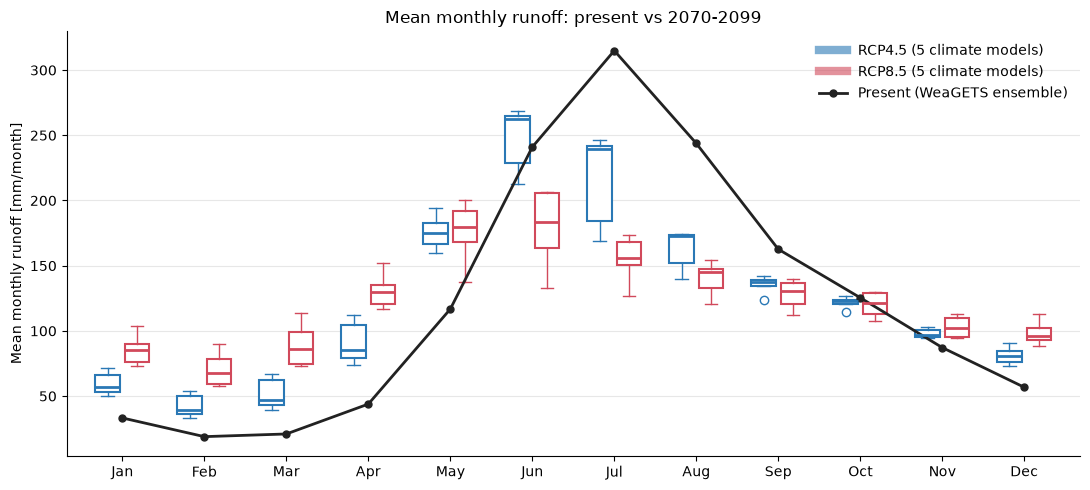

In [2]:
monthly_table = w2.plot_monthly_boxplot(
    results["monthly"], output_destination=FIG_DIR / f"{STATION}_{WEAGETS}_monthly_runoff_boxplot.png"
)
monthly_table

## Extremes: return period of the annual maximum daily runoff

For each realization a Gumbel distribution (maximum likelihood) is fitted to its 30 annual maxima.
Lines = median over the realizations (50 present, 250 per RCP), bands = 5-95%. Points = the empirical
Weibull plotting positions T = (n+1)/rank, median over the realizations per rank. Plotted up to T = 30 years
(the length of one realization).

Median [mm/d] 5-95% [mm/d]  Change vs present [%]
Group   T [years]                                                   
Present 2                   15.0    14.3-15.6                    0.0
        10                  19.4    18.2-20.6                    0.0
        30                  21.9    20.3-23.8                    0.0
RCP4.5  2                   13.5    11.8-14.8                   -9.8
        10                  17.7    15.3-19.5                   -8.7
        30                  20.2    17.3-22.5                   -7.7
RCP8.5  2                   12.2    10.3-13.4                  -18.7
        10                  16.0    13.4-17.8                  -17.6
        30                  18.2    15.2-20.7                  -17.0

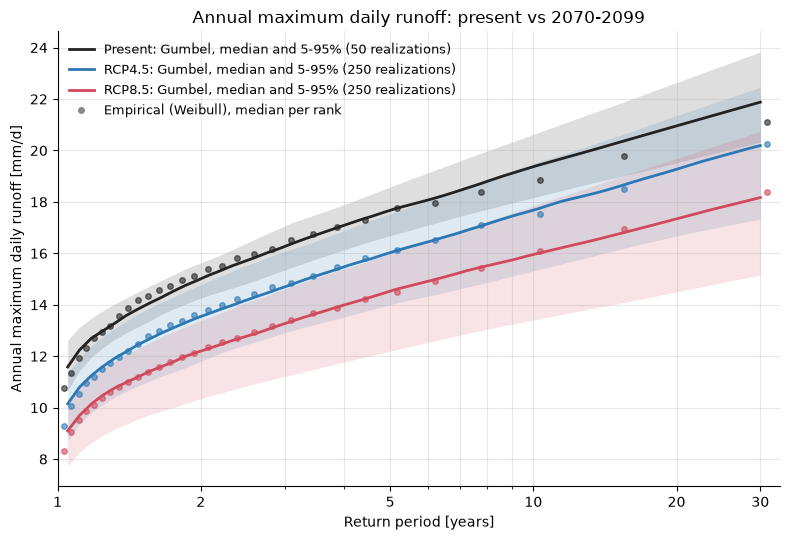

In [3]:
return_period_table = w2.plot_return_periods(
    results["annual_max"], max_return_period=30,
    output_destination=FIG_DIR / f"{STATION}_{WEAGETS}_return_periods.png",
)
return_period_table

### Mean annual maximum per climate model (for the discussion)

In [4]:
results["annual_max"].mean(axis=1).groupby(["group", "climate_model"]).describe(percentiles=[0.05, 0.5, 0.95])[
    ["5%", "50%", "95%"]
].round(1)

5%   50%   95%
group   climate_model                         
Present -                     14.6  15.4  16.1
RCP4.5  CLMCOM-CCLM4-ECEARTH  13.7  14.5  15.5
        CLMCOM-CCLM4-HADGEM   12.8  13.4  14.4
        DMI-HIRHAM-ECEARTH    13.4  14.2  15.1
        MPICSC-REMO1-MPIESM   13.5  14.3  15.3
        SMHI-RCA-IPSL         12.0  12.5  13.4
RCP8.5  CLMCOM-CCLM4-ECEARTH  12.8  13.4  14.3
        CLMCOM-CCLM4-HADGEM   12.3  12.8  13.5
        DMI-HIRHAM-ECEARTH    12.3  12.8  13.7
        MPICSC-REMO1-MPIESM   11.4  11.9  12.7
        SMHI-RCA-IPSL         10.4  10.9  11.4

## Task 3: partition of the uncertainty of the mean annual runoff

Same method as `tutorial.ipynb` (`UncertaintyAnalysis`), using the mean annual runoff of each of the
500 future realizations from the cached run above (no extra model run):
- Total (TU): 5-95% range of all 500 realizations
- Emission scenario (EU): |median RCP8.5 - median RCP4.5|
- Climate model (CMU): max - min of the 5 model means, averaged over the 2 RCPs
- Stochastic (SU): 5-95% range of the realizations of the median climate model, averaged over the 2 RCPs

Partition = each uncertainty / TU (the partitions do not have to add up to 1).

In [5]:
uncertainty_table = w2.uncertainty_partition(results["annual_mean"])
uncertainty_table

,Uncertainty [mm/yr],Partition [-]
Total (TU),283.95,1.00
Emission scenario (EU),4.90,0.02
Climate model (CMU),198.68,0.70
Stochastic (SU),85.61,0.30


In [6]:
# Mean annual runoff [mm/yr] per climate model and RCP (median and 5-95% over the realizations)
results["annual_mean"].groupby(["group", "climate_model"]).describe(percentiles=[0.05, 0.5, 0.95])[
    ["5%", "50%", "95%"]
].round(0)

5%     50%     95%
group   climate_model                               
Present -                     1428.0  1463.0  1510.0
RCP4.5  CLMCOM-CCLM4-ECEARTH  1496.0  1535.0  1585.0
        CLMCOM-CCLM4-HADGEM   1476.0  1512.0  1563.0
        DMI-HIRHAM-ECEARTH    1424.0  1461.0  1508.0
        MPICSC-REMO1-MPIESM   1454.0  1491.0  1539.0
        SMHI-RCA-IPSL         1367.0  1401.0  1448.0
RCP8.5  CLMCOM-CCLM4-ECEARTH  1548.0  1587.0  1639.0
        CLMCOM-CCLM4-HADGEM   1544.0  1583.0  1635.0
        DMI-HIRHAM-ECEARTH    1448.0  1484.0  1534.0
        MPICSC-REMO1-MPIESM   1347.0  1381.0  1427.0
        SMHI-RCA-IPSL         1290.0  1323.0  1367.0